In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np

In [2]:
#here we focus on the asymmetric baseline simulation
%cd /home/links/mf671/DATA/ERA5/falwa_data/

/home/links/mf671/DATA/ERA5/falwa_data


In [3]:
#import dataset with fluxes (output of falwa)
data = xr.open_mfdataset('/home/links/mf671/DATA/ERA5/falwa_data/falwa_output_per_month/falwa_output_daily_1.5x1.5_*.nc', parallel=True)
data = data.sel(latitude=slice(0, 90))

ucomp = data['u_baro'].values
uref = data['dw_uref'].values
qgpv = data['dw_qgpv'].values
qref = data['dw_qref'].values
lons = data['longitude'].values
lats = data['latitude'].values
times = data['valid_time'].values

print(len(data.valid_time))
data.close()

1805


In [4]:
print(qgpv.shape)

(1805, 61, 240)


In [5]:
i=0
j=35
k=35
diff = (qref[i,:] - qgpv[i,j,k])

In [6]:
print(diff[1:])

[-1.27714894e-04 -1.25439969e-04 -1.23205082e-04 -1.21042081e-04
 -1.18961838e-04 -1.16960052e-04 -1.14970423e-04 -1.12947549e-04
 -1.10878401e-04 -1.08742743e-04 -1.06529970e-04 -1.04124950e-04
 -1.01538295e-04 -9.86365354e-05 -9.54285716e-05 -9.19451571e-05
 -8.79685824e-05 -8.30807535e-05 -7.79817552e-05 -7.25592102e-05
 -6.68447468e-05 -6.08339355e-05 -5.43871432e-05 -4.78478245e-05
 -4.13149276e-05 -3.48642576e-05 -2.83648526e-05 -2.18204462e-05
 -1.52542582e-05 -8.61678105e-06 -1.89631497e-06  5.09692753e-06
  1.26418254e-05  2.04816398e-05  2.86823152e-05  3.72229300e-05
  4.59763541e-05  5.45947433e-05  6.30230610e-05  7.13093562e-05
  7.94309730e-05  8.78217635e-05  9.65559608e-05  1.05307972e-04
  1.14172335e-04  1.23192969e-04  1.32702472e-04  1.42792620e-04
  1.53291746e-04  1.63982519e-04  1.75212190e-04  1.87116466e-04
  2.00371303e-04  2.14562691e-04  2.29433787e-04  2.46049492e-04
  2.66812116e-04  2.94279114e-04  3.33916145e-04  3.85687754e-04]


In [7]:
min_index = np.argmin(abs(diff))
print("Index of minimum value:", min_index)
print("Minimum value:", diff[min_index])
print("Corresponding q:", qgpv[i,j,k])
print("Corresponding q_ref:", qref[i,min_index])

Index of minimum value: 31
Minimum value: -1.8963149745493282e-06
Corresponding q: 0.00013903602298959952
Corresponding q_ref: 0.0001371397080150502


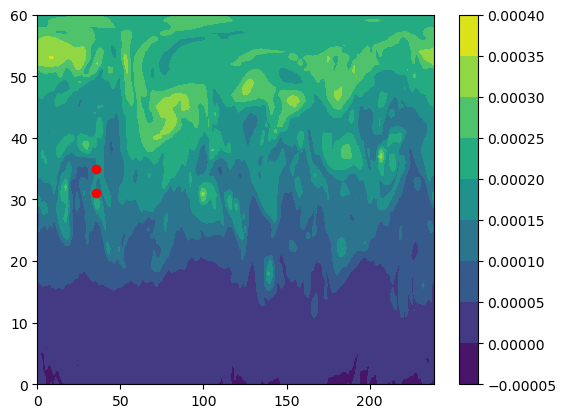

In [8]:
plt.contourf(qgpv[0,:,:])
plt.colorbar()
plt.plot(j, k, 'o', color='red')
plt.plot(j, min_index, 'o', color='red')

In [32]:
from tqdm import tqdm
ue = np.zeros(qgpv.shape)
for i,time in tqdm(enumerate(times)):
    for j,lat in enumerate(lats):
        for k,lon in enumerate(lons):
            diff = qref[i,:] - qgpv[i,j,k]
            min_index = np.argmin(abs(diff))
            ue[i,j,k] = ucomp[i,j,k] - uref[i,min_index]
            #print(j,min_index)

1805it [01:42, 17.55it/s]


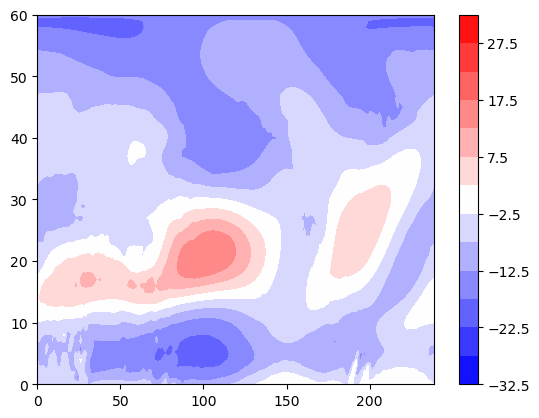

In [34]:
levels = np.arange(-32.5,33,5)
plt.contourf(ue[:,:,:].mean(axis=0),levels,cmap='bwr')
plt.colorbar()

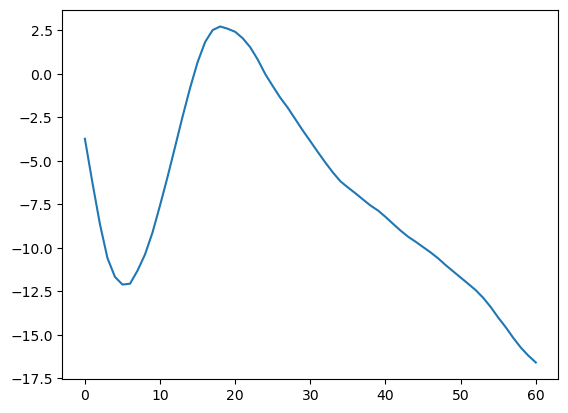

In [36]:
plt.plot(ue.mean(axis=(0,2)))

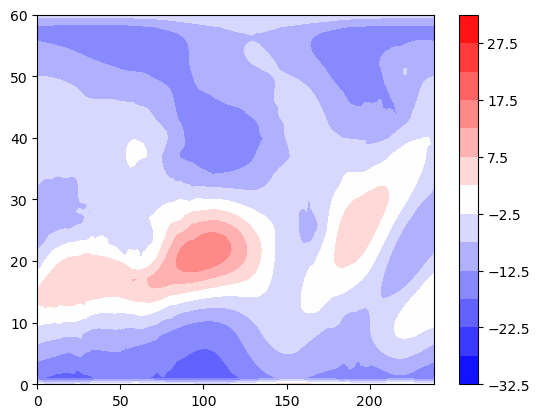

In [37]:
levels = np.arange(-32.5,33,5)
plt.contourf((ucomp-uref[:,:,np.newaxis]).mean(axis=0),levels,cmap='bwr')
plt.colorbar()

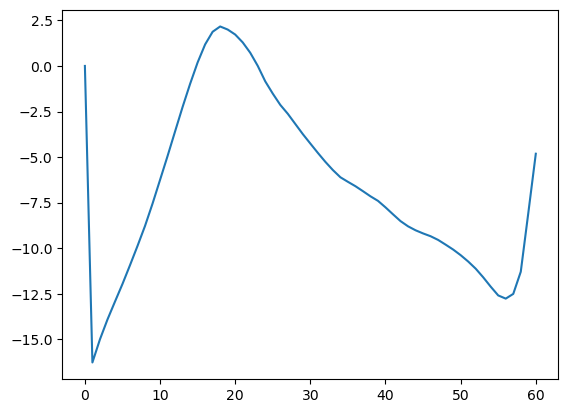

In [38]:
plt.plot((ucomp-uref[:,:,np.newaxis]).mean(axis=(0,2)))